In [2]:
# 导入数据处理和可视化库

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# 加载 UCI 信用卡违约数据集

credit = fetch_ucirepo(id=350)

# 获取特征和目标变量

X = credit.data.features.copy()
y = credit.data.targets.copy()

# 输出数据集基本信息

print("数据加载成功")
print("特征数据形状：", X.shape)
print("目标数据形状：", y.shape)

print("\n原始特征名称：")
print(X.columns.tolist())

print("\n原始目标名称：")
print(y.columns.tolist())

数据加载成功
特征数据形状： (30000, 23)
目标数据形状： (30000, 1)

原始特征名称：
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']

原始目标名称：
['Y']


In [3]:
# 按照 UCI 官方说明定义字段名称

column_mapping = {
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6"
}

# 检查原始字段是否与官方一致

assert set(X.columns) == set(column_mapping.keys()), "原始字段与官方定义不一致"
assert y.shape[1] == 1, "目标变量数量不正确"

# 重命名特征和目标变量

X = X.rename(columns=column_mapping)
y = y.rename(columns={y.columns[0]: "DEFAULT"})

# 输出修改后的字段名称

print("重命名后的特征：")
print(X.columns.tolist())

print("\n目标变量：")
print(y.columns.tolist())

重命名后的特征：
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

目标变量：
['DEFAULT']


In [4]:
# 查看前五条客户数据

print("前五条特征数据：")
display(X.head())

# 查看目标变量

print("\n前五条目标变量：")
display(y.head())

# 查看数据类型

print("\n特征数据类型：")
print(X.dtypes)

# 查看年龄与信用额度的统计信息

print("\n年龄统计：")
print(X["AGE"].describe())

print("\n信用额度统计：")
print(X["LIMIT_BAL"].describe())

前五条特征数据：


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679



前五条目标变量：


,DEFAULT
0,1
1,1
2,0
3,0
4,0



特征数据类型：
LIMIT_BAL    int64
SEX          int64
EDUCATION    int64
MARRIAGE     int64
AGE          int64
PAY_0        int64
PAY_2        int64
PAY_3        int64
PAY_4        int64
PAY_5        int64
PAY_6        int64
BILL_AMT1    int64
BILL_AMT2    int64
BILL_AMT3    int64
BILL_AMT4    int64
BILL_AMT5    int64
BILL_AMT6    int64
PAY_AMT1     int64
PAY_AMT2     int64
PAY_AMT3     int64
PAY_AMT4     int64
PAY_AMT5     int64
PAY_AMT6     int64
dtype: object

年龄统计：
count    30000.000000
mean        35.485500
std          9.217904
min         21.000000
25%         28.000000
50%         34.000000
75%         41.000000
max         79.000000
Name: AGE, dtype: float64

信用额度统计：
count      30000.000000
mean      167484.322667
std       129747.661567
min        10000.000000
25%        50000.000000
50%       140000.000000
75%       240000.000000
max      1000000.000000
Name: LIMIT_BAL, dtype: float64


In [5]:
# 统计数据缺失情况

print("特征缺失值总数：", X.isnull().sum().sum())
print("目标缺失值总数：", y.isnull().sum().sum())

# 检查完全重复的客户记录

df = pd.concat([X, y], axis=1)

duplicate_count = df.duplicated().sum()

print("完全重复记录数量：", duplicate_count)

# 查看违约类别数量和比例

target = y["DEFAULT"]

print("\n违约类别数量：")
print(target.value_counts().sort_index())

print("\n违约类别比例：")
print(
    (target.value_counts(normalize=True).sort_index() * 100).round(2)
)

特征缺失值总数： 0
目标缺失值总数： 0
完全重复记录数量： 35

违约类别数量：
DEFAULT
0    23364
1     6636
Name: count, dtype: int64

违约类别比例：
DEFAULT
0    77.88
1    22.12
Name: proportion, dtype: float64


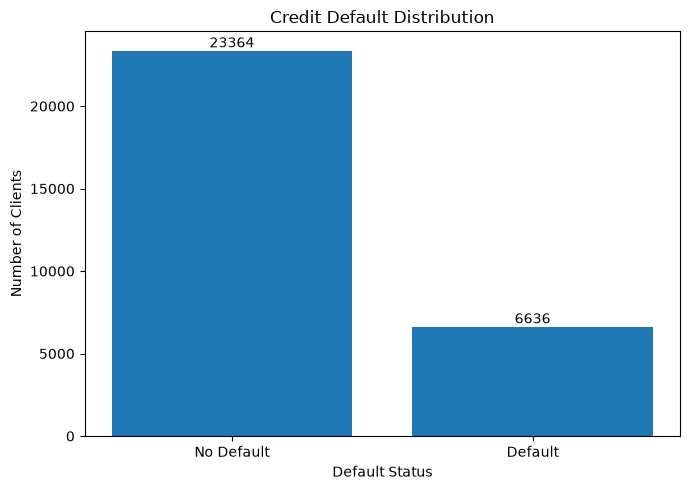

In [6]:
# 绘制违约类别分布图

import os

# 设置图片保存目录

figures_dir = "../results/figures"
os.makedirs(figures_dir, exist_ok=True)

# 统计违约类别数量

counts = target.value_counts().sort_index()

# 绘制柱状图

plt.figure(figsize=(7, 5))

plt.bar(["No Default", "Default"], counts.values)

plt.title("Credit Default Distribution")
plt.xlabel("Default Status")
plt.ylabel("Number of Clients")

# 显示每类样本数量

for i, value in enumerate(counts.values):
    plt.text(i, value + 200, str(value), ha="center")

plt.tight_layout()

# 保存图片

plt.savefig(
    os.path.join(figures_dir, "credit_default_distribution.png"),
    dpi=300
)

plt.show()

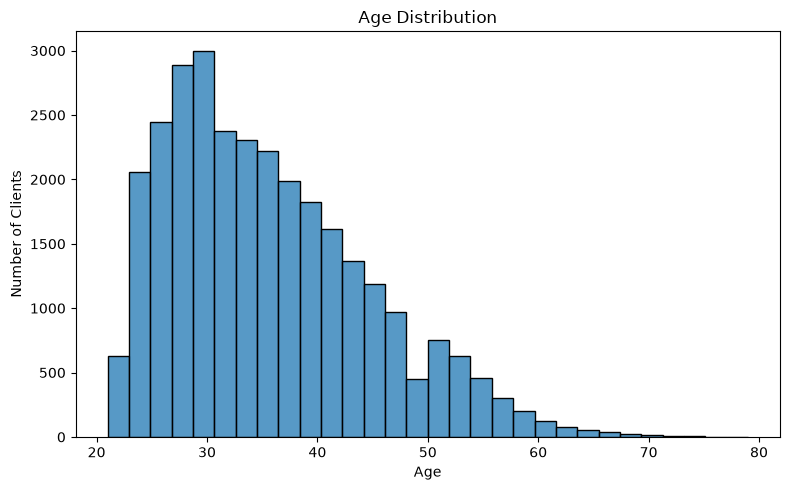

In [7]:
# 绘制客户年龄分布直方图

plt.figure(figsize=(8, 5))

sns.histplot(
    data=X,
    x="AGE",
    bins=30
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Clients")

plt.tight_layout()

# 保存图片

plt.savefig(
    os.path.join(figures_dir, "credit_age_distribution.png"),
    dpi=300
)

plt.show()

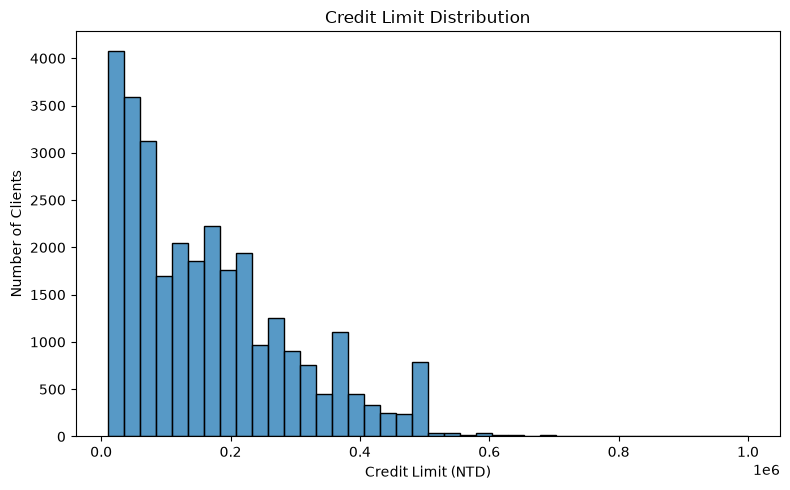

In [8]:
# 绘制信用额度分布直方图

plt.figure(figsize=(8, 5))

sns.histplot(
    data=X,
    x="LIMIT_BAL",
    bins=40
)

plt.title("Credit Limit Distribution")
plt.xlabel("Credit Limit (NTD)")
plt.ylabel("Number of Clients")

plt.tight_layout()

# 保存图片

plt.savefig(
    os.path.join(figures_dir, "credit_limit_distribution.png"),
    dpi=300
)

plt.show()

不同年龄段的违约率：
AGE_GROUP
Under 25    27.19
25-34       20.30
35-44       21.86
45-54       23.93
55+         26.69
Name: DEFAULT, dtype: float64


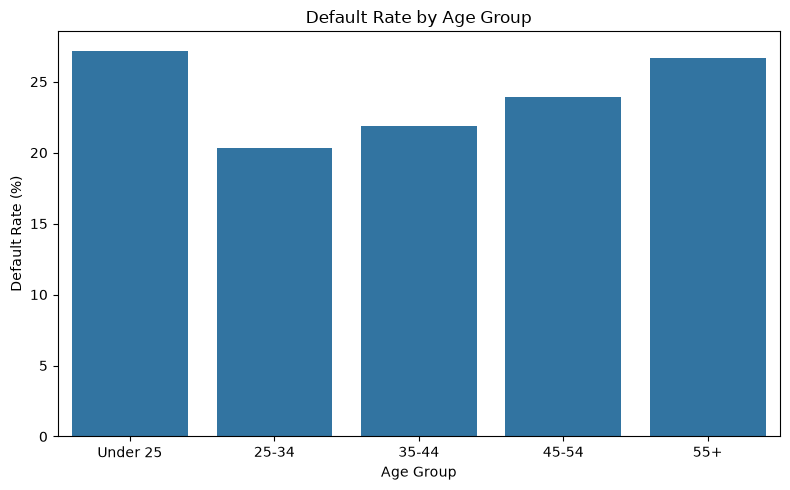

In [9]:
# 创建用于分析的完整数据表

df = X.copy()
df["DEFAULT"] = y["DEFAULT"]

# 按年龄划分客户群体

age_bins = [0, 25, 35, 45, 55, 100]
age_labels = ["Under 25", "25-34", "35-44", "45-54", "55+"]

df["AGE_GROUP"] = pd.cut(
    df["AGE"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# 计算各年龄段违约率

age_default_rate = (
    df.groupby("AGE_GROUP", observed=True)["DEFAULT"]
    .mean() * 100
)

print("不同年龄段的违约率：")
print(age_default_rate.round(2))

# 绘制不同年龄段的违约率

plt.figure(figsize=(8, 5))

sns.barplot(
    x=age_default_rate.index,
    y=age_default_rate.values
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")

plt.tight_layout()

# 保存图片

plt.savefig(
    "../results/figures/credit_default_by_age.png",
    dpi=300
)

plt.show()

不同信用额度组的违约率：
LIMIT_GROUP
(9999.999, 50000.0]      31.79
(50000.0, 100000.0]      25.80
(100000.0, 180000.0]     19.86
(180000.0, 270000.0]     16.86
(270000.0, 1000000.0]    13.80
Name: DEFAULT, dtype: float64


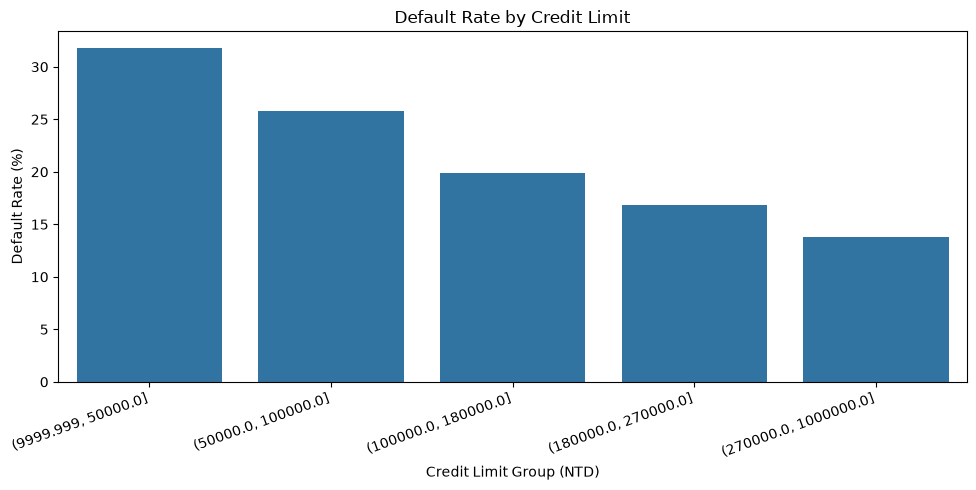

In [10]:
# 将客户按信用额度划分为五组

df["LIMIT_GROUP"] = pd.qcut(
    df["LIMIT_BAL"],
    q=5,
    duplicates="drop"
)

# 计算各信用额度组的违约率

limit_default_rate = (
    df.groupby("LIMIT_GROUP", observed=True)["DEFAULT"]
    .mean() * 100
)

print("不同信用额度组的违约率：")
print(limit_default_rate.round(2))

# 绘制信用额度与违约率的关系

plt.figure(figsize=(10, 5))

sns.barplot(
    x=[str(x) for x in limit_default_rate.index],
    y=limit_default_rate.values
)

plt.title("Default Rate by Credit Limit")
plt.xlabel("Credit Limit Group (NTD)")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=20, ha="right")

plt.tight_layout()

# 保存图片

plt.savefig(
    "../results/figures/credit_default_by_limit.png",
    dpi=300
)

plt.show()

各还款状态客户数量：
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

不同还款状态的违约率：
PAY_0
-2    13.23
-1    16.78
 0    12.81
 1    33.95
 2    69.14
 3    75.78
 4    68.42
 5    50.00
 6    54.55
 7    77.78
 8    57.89
Name: DEFAULT, dtype: float64


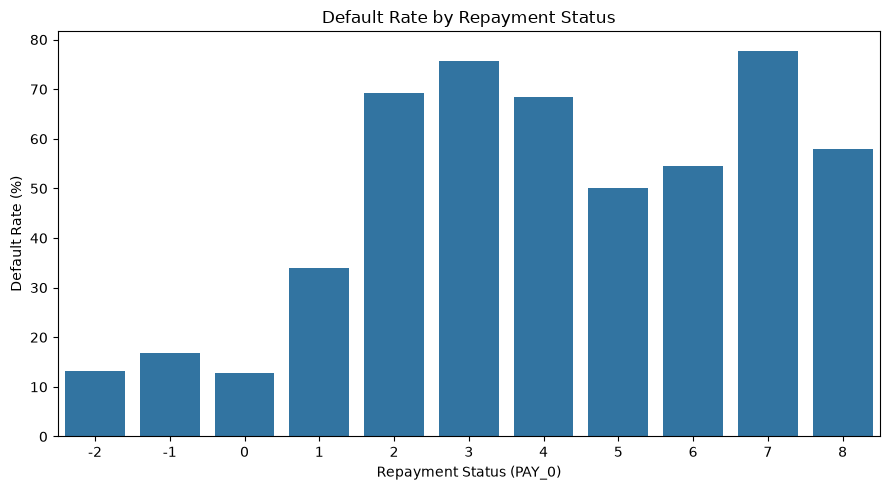

In [11]:
# 统计不同还款状态的客户数量

pay_counts = df["PAY_0"].value_counts().sort_index()

print("各还款状态客户数量：")
print(pay_counts)

# 计算各还款状态对应的违约率

pay_default_rate = (
    df.groupby("PAY_0")["DEFAULT"]
    .mean() * 100
)

print("\n不同还款状态的违约率：")
print(pay_default_rate.round(2))

# 绘制还款状态与违约率的关系

plt.figure(figsize=(9, 5))

sns.barplot(
    x=pay_default_rate.index.astype(str),
    y=pay_default_rate.values
)

plt.title("Default Rate by Repayment Status")
plt.xlabel("Repayment Status (PAY_0)")
plt.ylabel("Default Rate (%)")

plt.tight_layout()

# 保存图片

plt.savefig(
    "../results/figures/credit_default_by_payment_status.png",
    dpi=300
)

plt.show()

In [12]:
# 导入数据划分工具

from sklearn.model_selection import train_test_split

# 准备特征和目标变量

X_model = X.copy()
y_model = y["DEFAULT"].copy()

# 按类别比例划分训练集和测试集

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.2,
    random_state=42,
    stratify=y_model
)

# 查看数据集大小

print("训练集特征：", X_train.shape)
print("测试集特征：", X_test.shape)

print("训练集标签：", y_train.shape)
print("测试集标签：", y_test.shape)

训练集特征： (24000, 23)
测试集特征： (6000, 23)
训练集标签： (24000,)
测试集标签： (6000,)


In [13]:
# 检查原始数据的类别比例

print("原始数据类别比例：")
print(y_model.value_counts(normalize=True).sort_index().round(4))

# 检查训练集的类别比例

print("\n训练集类别比例：")
print(y_train.value_counts(normalize=True).sort_index().round(4))

# 检查测试集的类别比例

print("\n测试集类别比例：")
print(y_test.value_counts(normalize=True).sort_index().round(4))

原始数据类别比例：
DEFAULT
0    0.7788
1    0.2212
Name: proportion, dtype: float64

训练集类别比例：
DEFAULT
0    0.7788
1    0.2212
Name: proportion, dtype: float64

测试集类别比例：
DEFAULT
0    0.7788
1    0.2212
Name: proportion, dtype: float64


In [14]:
# 导入分层交叉验证工具

from sklearn.model_selection import StratifiedKFold

# 配置五折分层交叉验证

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 检查每一折的训练和验证样本数

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):
    print(f"第 {fold} 折")

    print("训练样本数：", len(train_idx))
    print("验证样本数：", len(val_idx))

    # 检查验证集中的违约比例

    val_rate = y_train.iloc[val_idx].mean()

    print(f"验证集违约比例：{val_rate:.4f}")
    print()

第 1 折
训练样本数： 19200
验证样本数： 4800
验证集违约比例：0.2210

第 2 折
训练样本数： 19200
验证样本数： 4800
验证集违约比例：0.2213

第 3 折
训练样本数： 19200
验证样本数： 4800
验证集违约比例：0.2213

第 4 折
训练样本数： 19200
验证样本数： 4800
验证集违约比例：0.2213

第 5 折
训练样本数： 19200
验证样本数： 4800
验证集违约比例：0.2213



In [15]:
# 定义连续数值特征

numeric_features = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

# 定义类别特征

categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

# 检查特征数量和名称

all_features = numeric_features + categorical_features

assert len(all_features) == 23
assert len(set(all_features)) == 23
assert set(all_features) == set(X_train.columns)

print("连续数值特征数量：", len(numeric_features))
print("类别特征数量：", len(categorical_features))
print("特征检查通过")

连续数值特征数量： 14
类别特征数量： 9
特征检查通过


In [16]:
# 导入预处理工具

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# 连续数值特征标准化

numeric_transformer = StandardScaler()

# 类别特征独热编码

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# 合并两种预处理方式

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("数据预处理器创建成功")
print(preprocessor)

数据预处理器创建成功
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2',
                                  'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5',
                                  'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2',
                                  'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5',
                                  'PAY_AMT6']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0',
                                  'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5',
                                  'PAY_6'])])


In [17]:
# 导入机器学习分类模型

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 定义三个分类模型

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=1
    )
}

# 为各模型创建完整流水线

pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

# 查看已创建的模型流水线

print("模型流水线创建成功：")

for name in pipelines:
    print(name)

模型流水线创建成功：
Logistic Regression
Decision Tree
Random Forest


In [19]:
# 导入交叉验证工具

from sklearn.model_selection import cross_validate

# 定义五个模型评价指标

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

print("评价指标：", list(scoring.keys()))

评价指标： ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']


In [20]:
# 保存各模型的交叉验证结果

cv_results = {}
comparison_results = []

# 依次训练和评价三个模型

for name, pipeline in pipelines.items():

    print(f"\n正在进行交叉验证：{name}")

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_results[name] = scores

    # 计算各评价指标的均值和标准差

    result = {"Model": name}

    for metric in scoring:

        values = scores[f"test_{metric}"]

        result[f"{metric}_Mean"] = values.mean()
        result[f"{metric}_Std"] = values.std()

    comparison_results.append(result)

    print(f"{name} 交叉验证完成")

# 生成模型对比表

cv_comparison = pd.DataFrame(comparison_results)

display(cv_comparison.round(4))


正在进行交叉验证：Logistic Regression
Logistic Regression 交叉验证完成

正在进行交叉验证：Decision Tree
Decision Tree 交叉验证完成

正在进行交叉验证：Random Forest
Random Forest 交叉验证完成


,Model,Accuracy_Mean,Accuracy_Std,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std,F1_Mean,F1_Std,ROC_AUC_Mean,ROC_AUC_Std
0,Logistic Regression,0.8205,0.0020,0.6790,0.0161,0.3583,0.0079,0.4688,0.0045,0.7689,0.0061
1,Decision Tree,0.8155,0.0024,0.6589,0.0221,0.3473,0.0163,0.4542,0.0086,0.7457,0.0073
2,Random Forest,0.8202,0.0016,0.6811,0.0112,0.3524,0.0044,0.4644,0.0034,0.7803,0.0038


In [21]:
# 查看各模型每一折的 F1 得分

for name, scores in cv_results.items():

    print(f"\n{name}")

    for i, score in enumerate(scores["test_F1"], start=1):
        print(f"第 {i} 折 F1：{score:.4f}")

    print(
        f"平均 F1：{scores['test_F1'].mean():.4f}"
    )

    print(
        f"F1 标准差：{scores['test_F1'].std():.4f}"
    )


Logistic Regression
第 1 折 F1：0.4739
第 2 折 F1：0.4675
第 3 折 F1：0.4704
第 4 折 F1：0.4715
第 5 折 F1：0.4609
平均 F1：0.4688
F1 标准差：0.0045

Decision Tree
第 1 折 F1：0.4538
第 2 折 F1：0.4464
第 3 折 F1：0.4456
第 4 折 F1：0.4559
第 5 折 F1：0.4695
平均 F1：0.4542
F1 标准差：0.0086

Random Forest
第 1 折 F1：0.4605
第 2 折 F1：0.4661
第 3 折 F1：0.4672
第 4 折 F1：0.4681
第 5 折 F1：0.4603
平均 F1：0.4644
F1 标准差：0.0034


In [22]:
# 保存交叉验证模型对比表

cv_comparison.to_csv(
    "../results/credit_cv_comparison.csv",
    index=False
)

print("模型交叉验证结果保存成功")

模型交叉验证结果保存成功


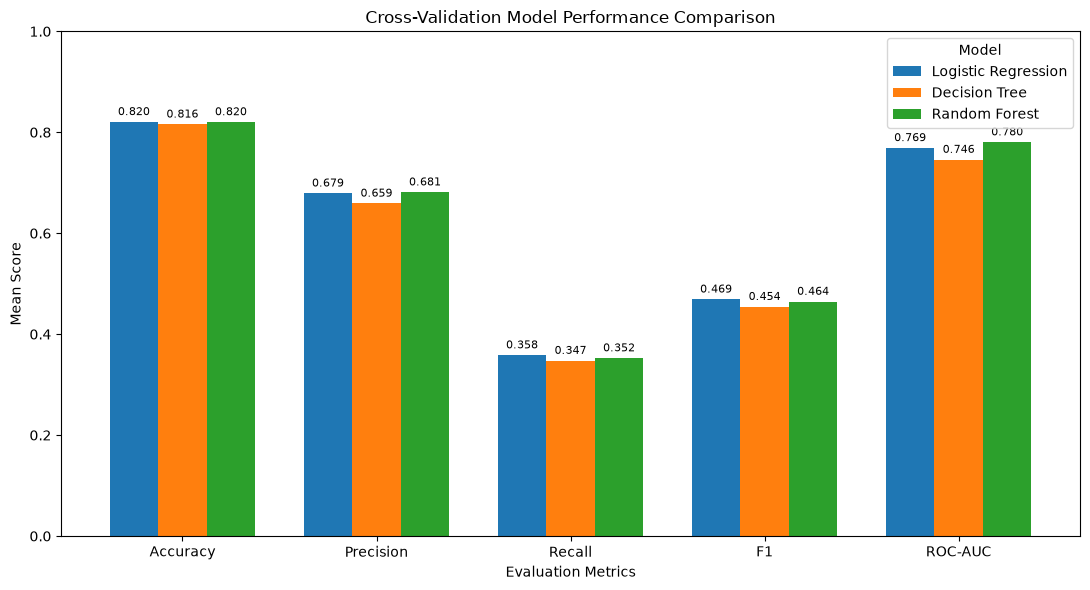

In [23]:
# 提取五项模型评价指标

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC"
]

# 整理模型对比数据

plot_data = cv_comparison.set_index("Model")[
    [f"{metric}_Mean" for metric in metrics]
].copy()

plot_data.columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

# 绘制模型性能对比柱状图

ax = plot_data.T.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

plt.title("Cross-Validation Model Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Mean Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Model", loc="upper right")

# 显示各模型的具体得分

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

plt.tight_layout()

# 保存模型性能对比图

plt.savefig(
    "../results/figures/credit_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

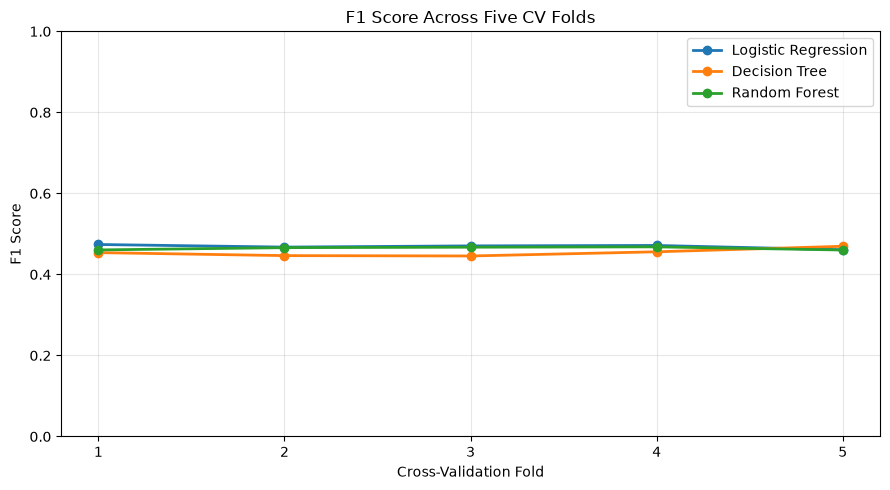

In [24]:
# 提取各模型五折交叉验证的 F1 得分

plt.figure(figsize=(9, 5))

for name, scores in cv_results.items():

    f1_scores = scores["test_F1"]

    plt.plot(
        range(1, 6),
        f1_scores,
        marker="o",
        linewidth=2,
        label=name
    )

# 设置图表标题和坐标轴

plt.title("F1 Score Across Five CV Folds")
plt.xlabel("Cross-Validation Fold")
plt.ylabel("F1 Score")

plt.xticks(range(1, 6))
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

# 保存五折 F1 对比图

plt.savefig(
    "../results/figures/credit_cv_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
# 导入模型评价工具

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

# 保存训练完成的模型和测试结果

trained_models = {}
test_predictions = {}
test_probabilities = {}
test_results = []

# 使用完整训练集训练三个模型

for name, pipeline in pipelines.items():

    print(f"正在训练：{name}")

    model = clone(pipeline)
    model.fit(X_train, y_train)

    # 使用独立测试集进行预测

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    trained_models[name] = model
    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob

    # 计算分类评价指标

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    }

    test_results.append(result)

    print(f"{name} 评价完成\n")

# 汇总独立测试集评价结果

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))

正在训练：Logistic Regression
Logistic Regression 评价完成

正在训练：Decision Tree
Decision Tree 评价完成

正在训练：Random Forest
Random Forest 评价完成



,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.8168,0.6615,0.3519,0.4594,0.7583
1,Decision Tree,0.8117,0.6446,0.3308,0.4373,0.7303
2,Random Forest,0.8157,0.6581,0.3466,0.4541,0.7721


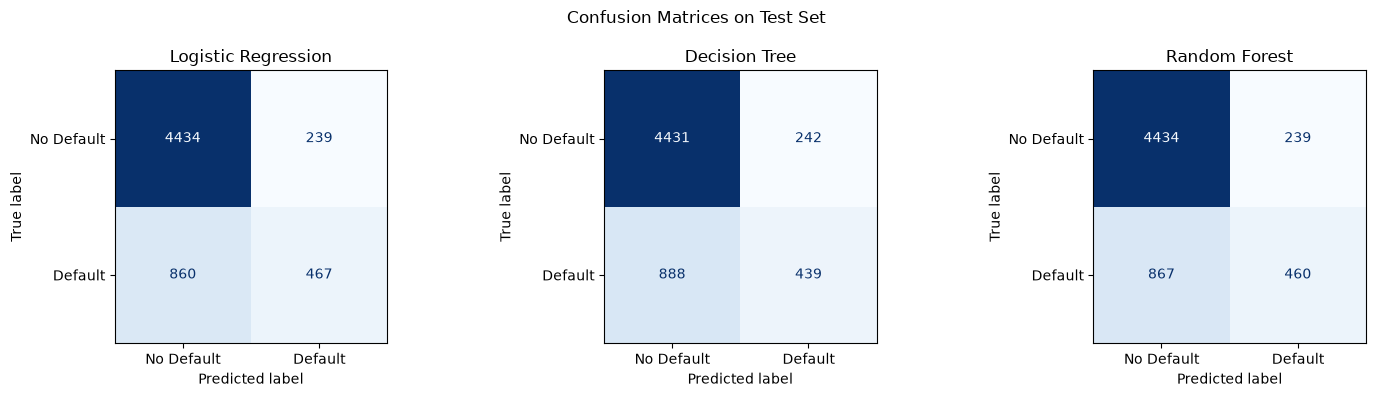

In [26]:
# 绘制三个模型的混淆矩阵

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(
    axes,
    test_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Default", "Default"]
    )

    display_cm.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices on Test Set")
plt.tight_layout()

# 保存混淆矩阵图片

plt.savefig(
    "../results/figures/credit_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

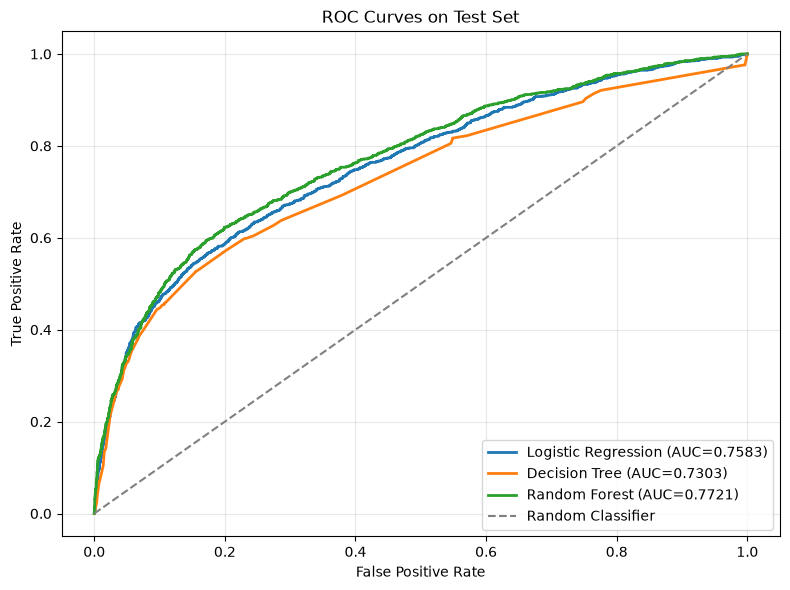

In [27]:
# 绘制三个模型的 ROC 曲线

plt.figure(figsize=(8, 6))

for name, y_prob in test_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC={auc_score:.4f})"
    )

# 绘制随机分类参考线

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curves on Test Set")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

# 保存 ROC 曲线图片

plt.savefig(
    "../results/figures/credit_roc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
# 保存独立测试集评价结果

test_comparison.to_csv(
    "../results/credit_test_comparison.csv",
    index=False
)

print("测试集模型对比表保存成功")

测试集模型对比表保存成功
